# MLT Assignment #2: FMA tracks, dimensionality reduction and clustering

Mironov Kirill, group J4132

Data: `fma_dataset_filtered.csv`, a filtered part of the [FMA](https://github.com/mdeff/fma) metadata with audio features of tracks from four genres.

What is done:
1. Loading the data.
2. Preprocessing.
3. 2D visualisation with PCA and t-SNE, coloured by genre.
4. PCA explained variance vs the number of components.
5. K-Means without `genre` for k from 2 to 6, k chosen by Silhouette and by Rand Index.
6. Answers to questions 6.1-6.5.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, rand_score, adjusted_rand_score
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.model_selection import cross_val_score
from sklearn.feature_selection import f_classif
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings('ignore', category=RuntimeWarning)

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

## 1. Data

In [2]:
df = pd.read_csv('fma_dataset_filtered.csv')
print('shape:', df.shape)
print('NaN values:', df.isna().sum().sum(), '| duplicated rows:', df.duplicated().sum())
display(df['genre'].value_counts().to_frame('tracks'))
df.iloc[:3, :8]

shape: (2406, 524)
NaN values: 0 | duplicated rows: 0


,tracks
genre,
Hip-Hop,910
Folk,874
Old-Time / Historic,357
Classical,265


,track_id,chroma_cens_kurtosis_01,chroma_cens_kurtosis_02,chroma_cens_kurtosis_03,chroma_cens_kurtosis_04,chroma_cens_kurtosis_05,chroma_cens_kurtosis_06,chroma_cens_kurtosis_07
0,2,7.180653,5.230309,0.249321,1.347620,1.482478,0.531371,1.481593
1,3,1.888963,0.760539,0.345297,2.295201,1.654031,0.067592,1.366848
2,5,0.527563,-0.077654,-0.279610,0.685883,1.937570,0.880839,-0.923192


Each `librosa` feature (MFCC, chroma, spectral features, ...) is given as 7 statistics over time: mean, median, std, min, max, skew, kurtosis. There are also four Echonest features: `duration`, `tempo`, `danceability`, `energy`.

In [3]:
def feature_group(col):
    parts = col.split('_')
    return '_'.join(parts[:-2]) if parts[-1].isdigit() else col

features = df.drop(columns=['track_id', 'genre'])
display(features.columns.to_series().map(feature_group).value_counts().to_frame('features'))

,features
mfcc,140
chroma_cens,84
chroma_cqt,84
chroma_stft,84
spectral_contrast,49
tonnetz,42
rmse,7
spectral_bandwidth,7
spectral_centroid,7
spectral_rolloff,7


## 2. Preprocessing

- `track_id` is just an id, so I drop it. `genre` is kept aside and used only to colour the plots and to compute the Rand Index.
- Columns with the same value for all tracks are removed.
- The features have very different scales: the chroma means and medians are in [0, 1], their kurtosis goes up to ~380, and `spectral_rolloff` is in Hz, up to 11 025. PCA, t-SNE and K-Means use Euclidean distances, so I standardise every feature to mean 0 and variance 1.

In [4]:
y = df['genre'].values
X = features.copy()

constant_cols = X.columns[X.nunique() == 1]
print('constant features removed:', list(constant_cols))
X = X.drop(columns=constant_cols)

X_scaled = StandardScaler().fit_transform(X)
print('feature matrix after preprocessing:', X_scaled.shape)

constant features removed: ['chroma_stft_max_04', 'chroma_stft_max_05', 'chroma_stft_max_07', 'chroma_stft_max_10']
feature matrix after preprocessing: (2406, 518)


## 3. Visualisation: PCA vs t-SNE

To compare the two pictures with numbers, I compute the cross-validated accuracy of a 5-NN genre classifier on the 2D coordinates and the silhouette of the true genres in 2D. Higher means the genres are better separated.

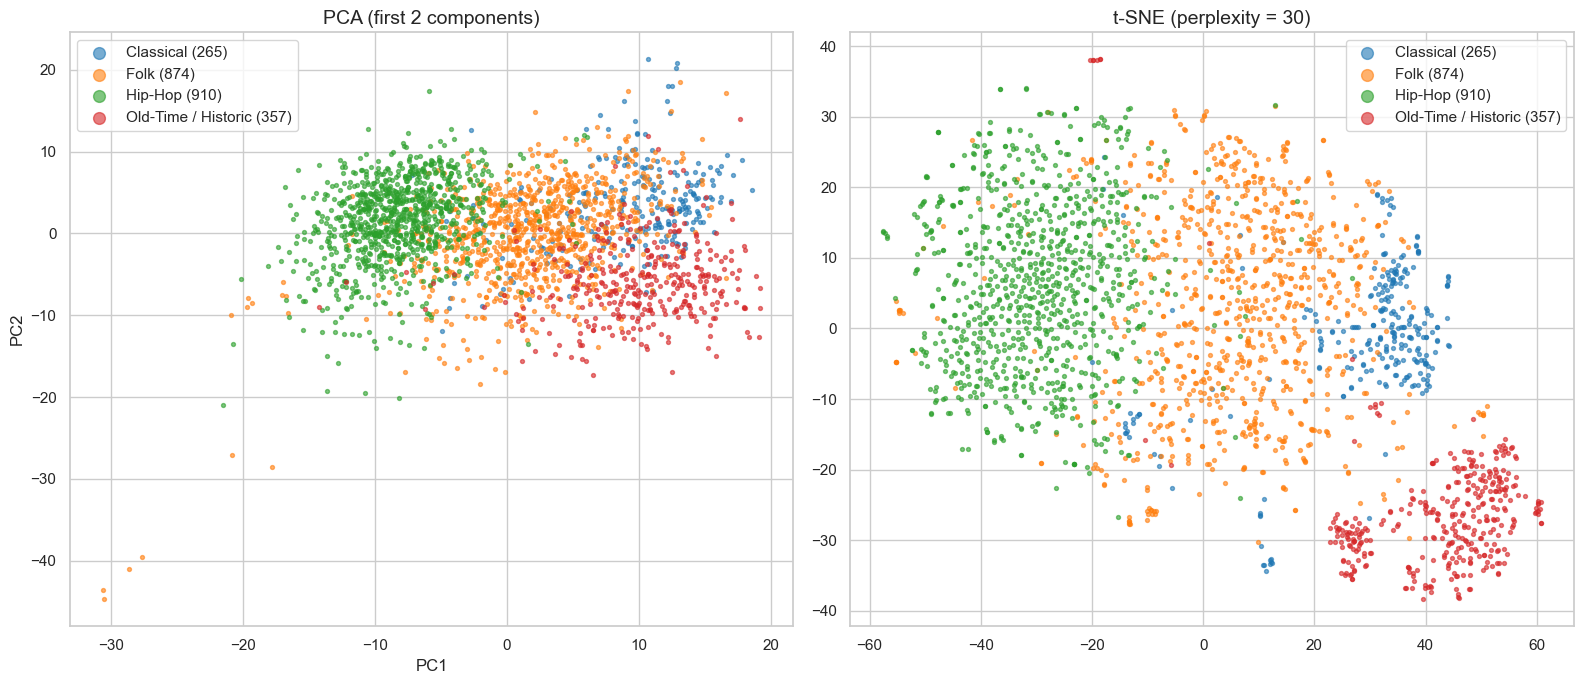

,5-NN genre accuracy (5-fold CV),silhouette of true genres
PCA 2D,0.758,0.195
t-SNE 2D,0.874,0.305


In [5]:
X_pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_scaled)
X_tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=RANDOM_STATE).fit_transform(X_scaled)

genres = sorted(np.unique(y))
palette = dict(zip(genres, sns.color_palette('tab10', len(genres))))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, emb, title in [(axes[0], X_pca2, 'PCA (first 2 components)'), (axes[1], X_tsne, 't-SNE (perplexity = 30)')]:
    for g in genres:
        m = y == g
        ax.scatter(emb[m, 0], emb[m, 1], s=8, alpha=0.6, color=palette[g], label=f'{g} ({m.sum()})')
    ax.set_title(title, fontsize=14)
    ax.legend(markerscale=3)
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
plt.tight_layout(); plt.show()

embedding_scores = pd.DataFrame({
    name: {'5-NN genre accuracy (5-fold CV)': cross_val_score(KNeighborsClassifier(5), emb, y, cv=5).mean(),
           'silhouette of true genres': silhouette_score(emb, y)}
    for name, emb in [('PCA 2D', X_pca2), ('t-SNE 2D', X_tsne)]}).T
embedding_scores.round(3)

## 4. PCA explained variance

PCA with all components. There are 2406 tracks and 518 features, so there are **518** components. The dotted line is PCA without standardisation, for comparison.

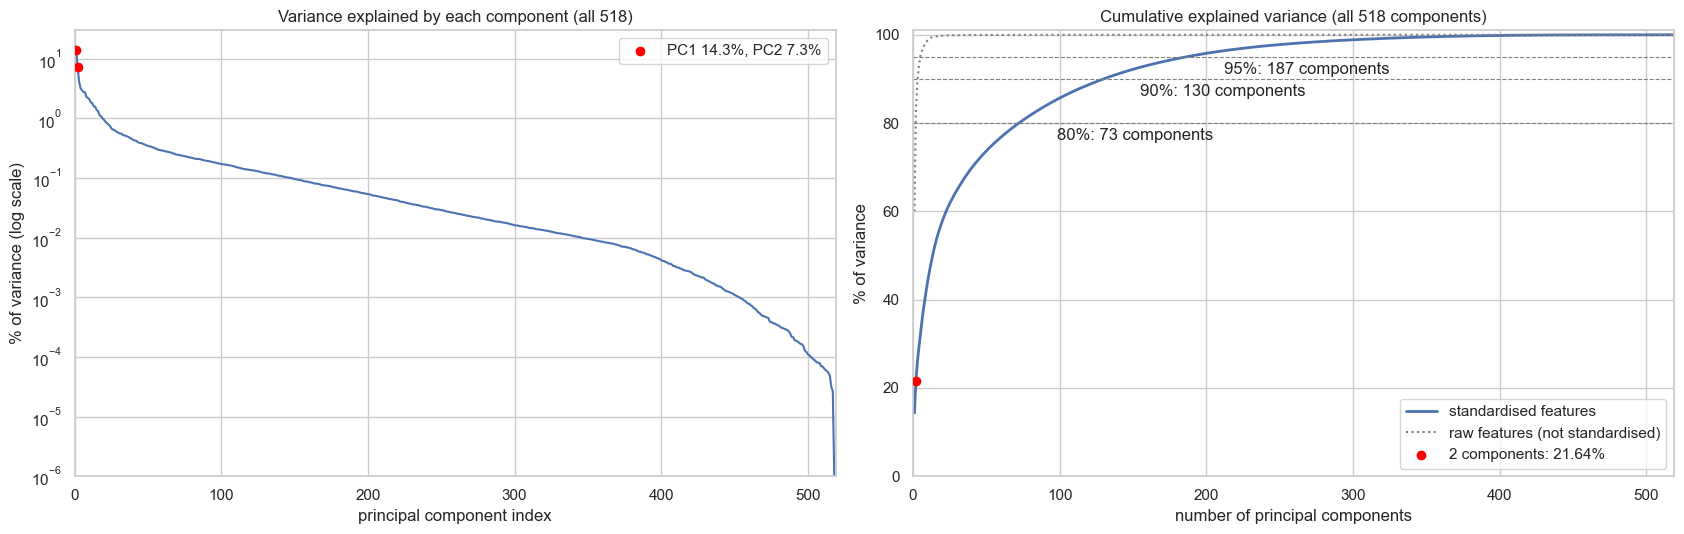

components: 518 (zero-variance: 1, caused by a linear dependence between features)
PC1 = 14.33%, PC2 = 7.31%, PC1 + PC2 = 21.64%  ->  lost: 78.36%
components needed: {'50%': 14, '80%': 73, '90%': 130, '95%': 187, '99%': 308}
raw (unscaled) features: first 2 components would give 83.0%


In [6]:
pca_full = PCA().fit(X_scaled)                   
evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)
n_comp = pca_full.n_components_
k_axis = np.arange(1, n_comp + 1)
needed = {t: int(np.searchsorted(cum_evr, t) + 1) for t in [0.5, 0.8, 0.9, 0.95, 0.99]}
cum_evr_raw = np.cumsum(PCA().fit(X.values).explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
axes[0].plot(k_axis, np.clip(evr * 100, 1e-6, None), lw=1.5)
axes[0].set_yscale('log'); axes[0].set_ylim(1e-6, 30); axes[0].set_xlim(0, n_comp + 1)
axes[0].scatter([1, 2], evr[:2] * 100, color='red', zorder=3, label=f'PC1 {evr[0]*100:.1f}%, PC2 {evr[1]*100:.1f}%')
axes[0].set_title(f'Variance explained by each component (all {n_comp})')
axes[0].set_xlabel('principal component index'); axes[0].set_ylabel('% of variance (log scale)')
axes[0].legend()

axes[1].plot(k_axis, cum_evr * 100, lw=2, label='standardised features')
axes[1].plot(k_axis, cum_evr_raw * 100, ls=':', color='gray', label='raw features (not standardised)')
axes[1].scatter([2], [cum_evr[1] * 100], color='red', zorder=3, label=f'2 components: {cum_evr[1] * 100:.2f}%')
for t in (0.8, 0.9, 0.95):
    axes[1].axhline(t * 100, ls='--', lw=0.8, color='gray')
    axes[1].annotate(f'{int(t * 100)}%: {needed[t]} components', (needed[t], t * 100),
                     xytext=(needed[t] + 25, t * 100 - 3.8))
axes[1].set_title(f'Cumulative explained variance (all {n_comp} components)')
axes[1].set_xlabel('number of principal components'); axes[1].set_ylabel('% of variance')
axes[1].set_xlim(0, n_comp + 1); axes[1].set_ylim(0, 101)
axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()

print(f'components: {n_comp} (zero-variance: {(evr < 1e-12).sum()}, caused by a linear dependence between features)')
print(f'PC1 = {evr[0]*100:.2f}%, PC2 = {evr[1]*100:.2f}%, PC1 + PC2 = {cum_evr[1]*100:.2f}%  ->  lost: {100 - cum_evr[1]*100:.2f}%')
print('components needed:', {f'{int(t*100)}%': n for t, n in needed.items()})
print(f'raw (unscaled) features: first 2 components would give {cum_evr_raw[1]*100:.1f}%')

## 5. K-Means for k = 2 … 6

- Silhouette uses only the data: for each track it compares the mean distance to its own cluster and to the nearest other cluster.
- Rand Index compares the clusters with the genres: it is the share of track pairs where both agree (the pair is together in both or separated in both).
- I also add the Adjusted Rand Index, which is corrected for chance (0 for a random partition, 1 for the genres). It is needed in 6.3.

,Silhouette,Rand Index,Adjusted Rand Index,cluster sizes
k,,,,
2,0.1096,0.6803,0.3605,"[1208, 1198]"
3,0.0899,0.7856,0.5271,"[1125, 870, 411]"
4,0.0756,0.7740,0.4545,"[815, 775, 428, 388]"
5,0.0718,0.8047,0.5071,"[776, 589, 421, 366, 254]"
6,0.0721,0.8048,0.5062,"[767, 589, 416, 363, 267, 4]"


best k: Silhouette -> 2, Rand Index -> 6, Adjusted Rand Index -> 3


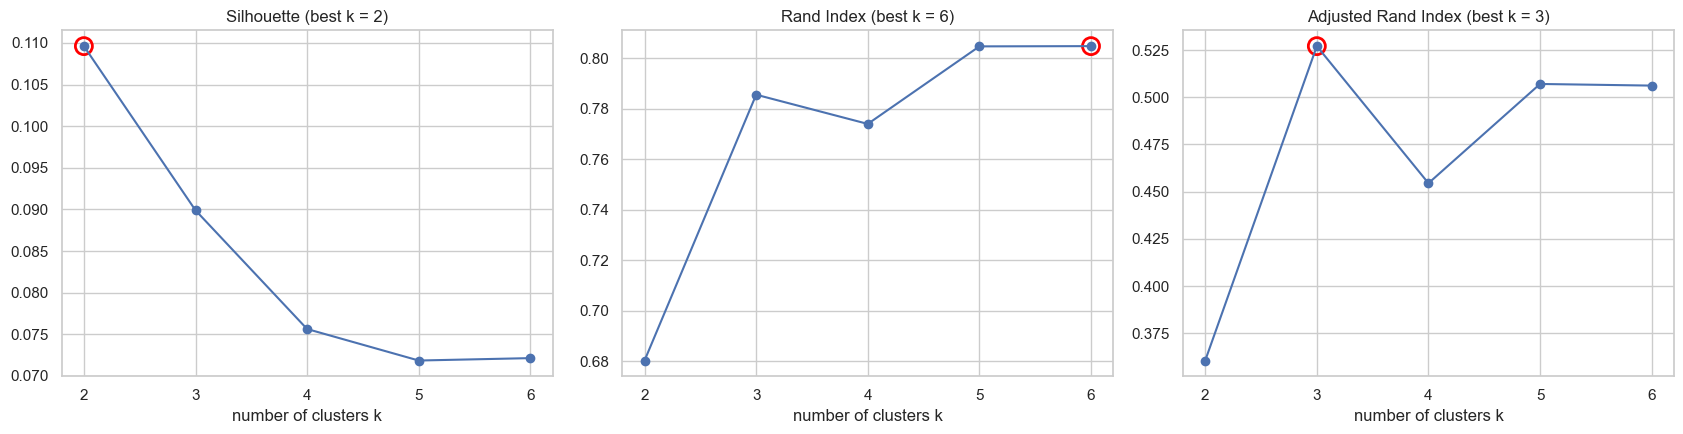

In [7]:
ks = range(2, 7)
results, labels_by_k = [], {}
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    labels_by_k[k] = km.labels_
    results.append({'k': k,
                    'Silhouette': silhouette_score(X_scaled, km.labels_),
                    'Rand Index': rand_score(y, km.labels_),
                    'Adjusted Rand Index': adjusted_rand_score(y, km.labels_),
                    'cluster sizes': sorted(np.bincount(km.labels_).tolist(), reverse=True)})
scores = pd.DataFrame(results).set_index('k')
display(scores.round(4))

best_sil = scores['Silhouette'].idxmax()
best_ri = scores['Rand Index'].idxmax()
best_ari = scores['Adjusted Rand Index'].idxmax()
print(f'best k: Silhouette -> {best_sil}, Rand Index -> {best_ri}, Adjusted Rand Index -> {best_ari}')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, best in zip(axes, ['Silhouette', 'Rand Index', 'Adjusted Rand Index'], [best_sil, best_ri, best_ari]):
    ax.plot(list(ks), scores[col], 'o-')
    ax.scatter([best], [scores.loc[best, col]], s=150, facecolors='none', edgecolors='red', linewidths=2)
    ax.set_title(f'{col} (best k = {best})'); ax.set_xlabel('number of clusters k'); ax.set_xticks(list(ks))
plt.tight_layout(); plt.show()

Genre × cluster tables and the clusters on the t-SNE map.

k = 2


cluster,0,1
genre,,
Classical,250,15
Folk,593,281
Hip-Hop,15,895
Old-Time / Historic,350,7


k = 3


cluster,0,1,2
genre,,,
Classical,10,16,239
Folk,58,216,600
Hip-Hop,1,886,23
Old-Time / Historic,342,7,8


k = 4


cluster,0,1,2,3
genre,,,,
Classical,10,233,14,8
Folk,92,519,223,40
Hip-Hop,712,15,183,0
Old-Time / Historic,1,8,8,340


k = 6


cluster,0,1,2,3,4,5
genre,,,,,,
Classical,6,205,6,11,37,0
Folk,24,190,71,63,522,4
Hip-Hop,0,9,182,692,27,0
Old-Time / Historic,333,12,8,1,3,0


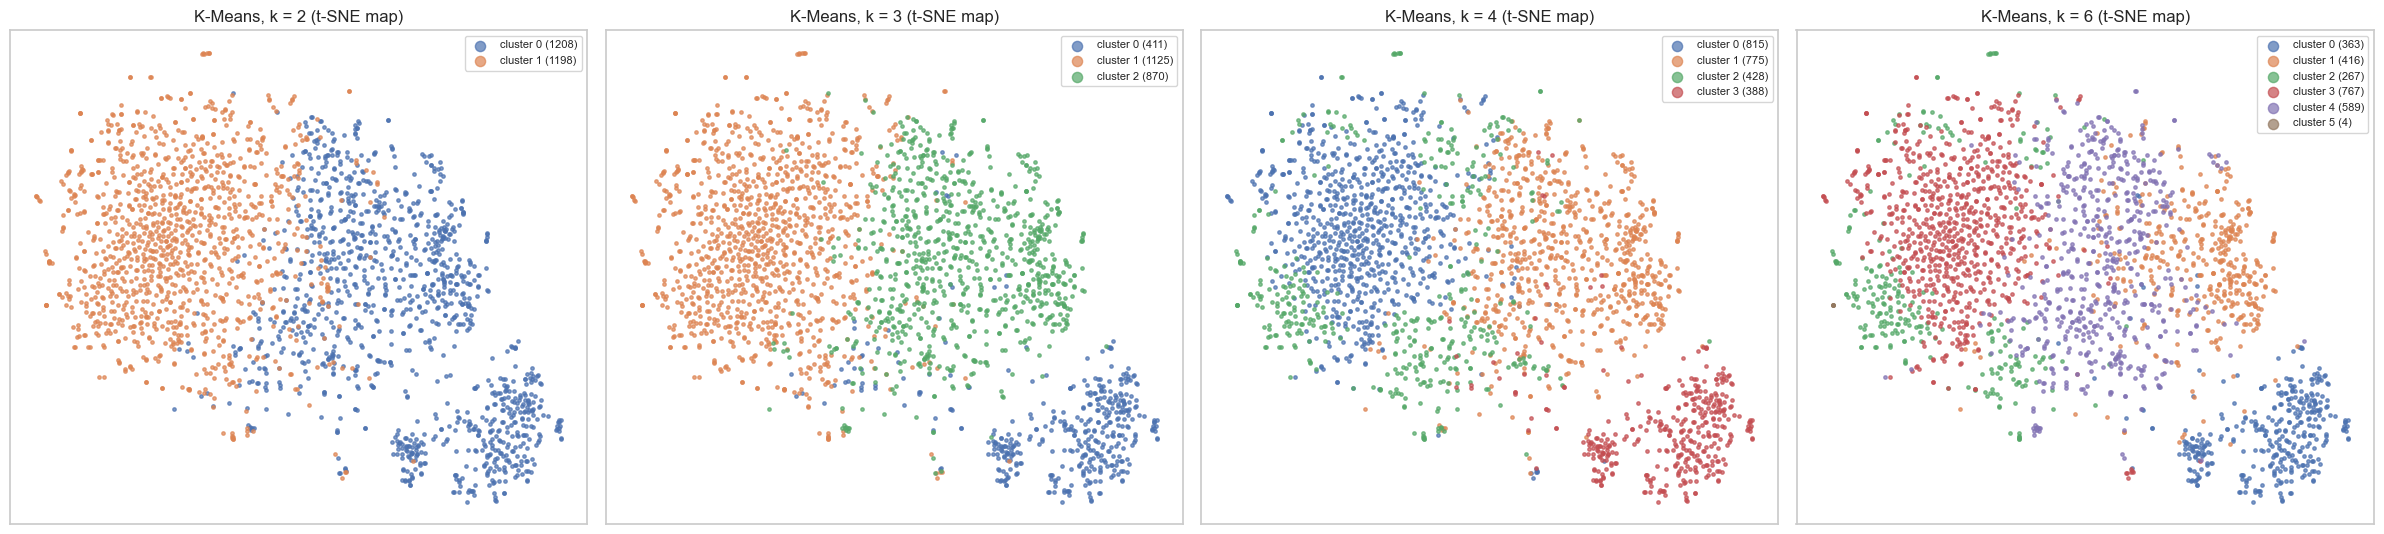

In [8]:
shown_k = sorted({best_sil, best_ri, best_ari, 4})
for k in shown_k:
    print(f'k = {k}')
    display(pd.crosstab(pd.Series(y, name='genre'), pd.Series(labels_by_k[k], name='cluster')))

fig, axes = plt.subplots(1, len(shown_k), figsize=(6 * len(shown_k), 5.5))
for ax, k in zip(np.atleast_1d(axes), shown_k):
    for c in range(k):
        m = labels_by_k[k] == c
        ax.scatter(X_tsne[m, 0], X_tsne[m, 1], s=6, alpha=0.7, color=f'C{c}', label=f'cluster {c} ({m.sum()})')
    ax.legend(markerscale=3, fontsize=8, loc='upper right')
    ax.set_title(f'K-Means, k = {k} (t-SNE map)')
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### 5.1. Check: near-constant features and outliers

At k = 6 one cluster is tiny. 20 features have the same value for more than 90% of the tracks (12 `chroma_cqt_max_*` and 8 `chroma_stft_max_*`, because the maximum of a normalised chroma is almost always 1), and the skew/kurtosis features have heavy tails. After standardisation some tracks are ~50 standard deviations away from the mean, and K-Means gives them a separate centroid.

So I drop the near-constant features, clip the standardised values to ±5 and run K-Means again.

In [9]:
majority_share = X.apply(lambda c: c.value_counts(normalize=True).iloc[0])
near_constant = majority_share[majority_share > 0.9].index
print(f'near-constant features: {len(near_constant)}; max |z| in X_scaled: {np.abs(X_scaled).max():.1f}')
X_robust = np.clip(StandardScaler().fit_transform(X.drop(columns=near_constant)), -5, 5)

robust = []
for k in ks:
    lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_robust)
    robust.append({'k': k, 'Silhouette': silhouette_score(X_robust, lab), 'Rand Index': rand_score(y, lab),
                   'Adjusted Rand Index': adjusted_rand_score(y, lab),
                   'cluster sizes': sorted(np.bincount(lab).tolist(), reverse=True)})
robust = pd.DataFrame(robust).set_index('k')
display(robust.round(4))
print(f'best k after robust cleaning: Silhouette -> {robust["Silhouette"].idxmax()}, '
      f'Rand Index -> {robust["Rand Index"].idxmax()}, Adjusted Rand Index -> {robust["Adjusted Rand Index"].idxmax()}')

near-constant features: 20; max |z| in X_scaled: 49.0


,Silhouette,Rand Index,Adjusted Rand Index,cluster sizes
k,,,,
2,0.1145,0.6810,0.3619,"[1211, 1195]"
3,0.0974,0.7829,0.5216,"[1135, 860, 411]"
4,0.0794,0.7748,0.4547,"[805, 756, 462, 383]"
5,0.0774,0.8062,0.5103,"[767, 595, 413, 367, 264]"
6,0.0745,0.7932,0.4614,"[750, 422, 376, 369, 278, 211]"


best k after robust cleaning: Silhouette -> 2, Rand Index -> 5, Adjusted Rand Index -> 3


After this cleaning the tiny cluster disappears (the smallest cluster at k = 6 has 211 tracks instead of 4), and the best k by Rand Index becomes 5 instead of 6. Silhouette still chooses k = 2 and ARI k = 3. The answers below use the standard preprocessing from section 2.

## 6. Answers

### 6.1. Do the visualisations reflect the real genre distribution? Which algorithm performs better and why?

Partly. t-SNE shows the genres much better than PCA.

On PCA the genres go along PC1: *Old-Time / Historic* and *Classical* on one side, *Folk* in the middle, *Hip-Hop* on the other side. But the clouds overlap a lot, and *Classical* is almost entirely inside *Folk* and *Old-Time*.

On t-SNE *Old-Time / Historic* is a separate island, *Classical* is a dense group next to *Folk*, and *Hip-Hop* has its own big region. Most of the mixing that is left is on the border between *Folk* and *Hip-Hop*.

The numbers from section 3 agree: 5-NN on the 2D coordinates gets **0.87** accuracy on t-SNE and **0.76** on PCA, and the genre silhouette is 0.31 vs 0.20.

The reason is that PCA is a linear projection onto the two directions with the largest variance. They keep only ~22% of the variance (see 6.2), and they don't have to be the directions where the genres differ. t-SNE is non-linear and tries to keep the nearest neighbours of every track close, so similar tracks end up together.

t-SNE has its drawbacks: only the local structure means something (distances between islands and their sizes don't), the result depends on `perplexity` and the seed, and new tracks can't be added without refitting. PCA is deterministic and can transform new data, so in 6.4 I use PCA.

### 6.2. What percentage of the explained variance is left if all but 2 components are excluded?

Two of the 518 components keep **21.64%** of the variance of the standardised features (PC1 14.33%, PC2 7.31%), so about 78.4% is lost.

The cumulative curve grows slowly: 80% of the variance needs 73 components, 90% needs 130, 95% needs 187 and 99% needs 308. So a 2D PCA picture of this data is very rough.

Without standardisation (dotted line) two components would keep ~83%, but only because the Hz features (`spectral_rolloff`, `spectral_centroid`) have huge values.

### 6.3. Can Silhouette be the criterion for the number of clusters here? Is the Rand Index more appropriate?

Silhouette is best at **k = 2** (0.110). All values are small, 0.07-0.11 (well separated clusters usually give more than 0.5), so the data has no clear clusters. At k = 2 the tracks split into loud/energetic ones (895 of the 910 *Hip-Hop* tracks) and quiet/acoustic ones (almost all *Classical* and *Old-Time* and two thirds of *Folk*). This is a real split of the data, but it doesn't give four genres. So Silhouette can be used when there are no labels, but here it doesn't find the genres.

Rand Index is best at **k = 6** (0.8048). It compares the clusters with the genres, so it fits better if the goal is to match the genres. But k = 6 is not a reliable choice:
- k = 5 gives 0.8047, practically the same;
- the plain Rand Index grows with k: about 69% of all pairs are from different genres, so with more clusters more pairs are separated "correctly" automatically;
- one of the six clusters has only 4 outlier tracks, and without the outliers (5.1) the best k is 5.

ARI, which is corrected for chance, chooses **k = 3**: *Hip-Hop*, *Old-Time*, and *Classical* together with *Folk*.

So to measure agreement with the genres an external index is better (ARI rather than plain RI). But it needs labels, and with labels this is already classification. Without labels Silhouette is one of the few options, and here it shows that the audio features don't form well separated groups.

### 6.4. How would you build a song recommendation system without knowing the genres?

I would make a content-based recommender with nearest neighbours on the audio features:

1. The same preprocessing as above (drop constant columns, standardise).
2. PCA to ~90% of the variance (130 components), to remove noise and correlated features.
3. For a song, find the closest songs by cosine similarity in this space and recommend the top N. For a big catalogue an approximate search (FAISS, Annoy) would be needed.
4. Feature groups can be weighted differently depending on what "similar" should mean: timbre (MFCC), harmony (chroma, tonnetz), rhythm (tempo, danceability). K-Means clusters can be used to make the list more diverse or to start with new users.
5. Quality is measured by user feedback (likes, skips, A/B tests). When there is listening history, it can be combined with collaborative filtering.

Below is a small version of steps 1-3. It never sees the genre, but most recommendations have the same genre as the query track.

In [10]:
pca90 = PCA(n_components=0.90, random_state=RANDOM_STATE).fit(X_scaled)
song_space = pca90.transform(X_scaled)
nn = NearestNeighbors(n_neighbors=11, metric='cosine').fit(song_space)
_, neighbour_idx = nn.kneighbors(song_space)
neighbour_idx = neighbour_idx[:, 1:]                 # drop the query track itself

same_genre = (y[neighbour_idx] == y[:, None]).mean()
chance = sum((np.mean(y == g)) ** 2 for g in genres)
print(f'PCA space: {pca90.n_components_} components (90% of variance)')
print(f'share of the 10 recommendations with the same genre as the query: {same_genre:.1%} (random: {chance:.1%})')

def recommend(track_id, n=5):
    i = int(np.flatnonzero(df['track_id'].values == track_id)[0])
    print(f'query: track {track_id} ({y[i]})')
    return df.iloc[neighbour_idx[i, :n]][['track_id', 'genre']]

recommend(df['track_id'].iloc[0])

PCA space: 130 components (90% of variance)
share of the 10 recommendations with the same genre as the query: 86.5% (random: 30.9%)
query: track 2 (Hip-Hop)


,track_id,genre
343,7492,Hip-Hop
1710,32484,Hip-Hop
1706,32480,Hip-Hop
1734,32660,Hip-Hop
654,11854,Hip-Hop


### 6.5*. Which original feature is the most important for the cluster division?

K-Means doesn't give feature importance, so I look at it in two ways:
1. ANOVA F-statistic of every standardised feature against the cluster labels: how different the cluster means are compared to the spread inside the clusters.
2. A random forest that predicts the cluster from the original features. Its importances are summed per feature and per feature group.

,top feature (ANOVA F),next by F,top 5 by random forest,top groups by random forest
k,,,,
2,energy (F = 2224),"mfcc_median_10, mfcc_mean_10, spectral_contrast_mean_04, spectral_contrast_median_04","spectral_contrast_mean_04, mfcc_median_06, energy, spectral_contrast_median_04, mfcc_mean_10","mfcc 0.34, chroma_stft 0.20, spectral_contrast 0.20"
4,mfcc_mean_04 (F = 1483),"mfcc_median_04, mfcc_max_04, mfcc_median_08, mfcc_mean_08","spectral_contrast_mean_04, spectral_contrast_mean_03, mfcc_mean_08, mfcc_max_04, mfcc_mean_04","mfcc 0.40, spectral_contrast 0.15, chroma_cqt 0.09"
6,mfcc_kurtosis_01 (F = 4501),"chroma_stft_min_11, chroma_stft_min_10, mfcc_mean_04, mfcc_median_04","mfcc_mean_04, mfcc_mean_07, mfcc_max_04, mfcc_mean_08, spectral_contrast_mean_04","mfcc 0.42, spectral_contrast 0.13, chroma_stft 0.10"


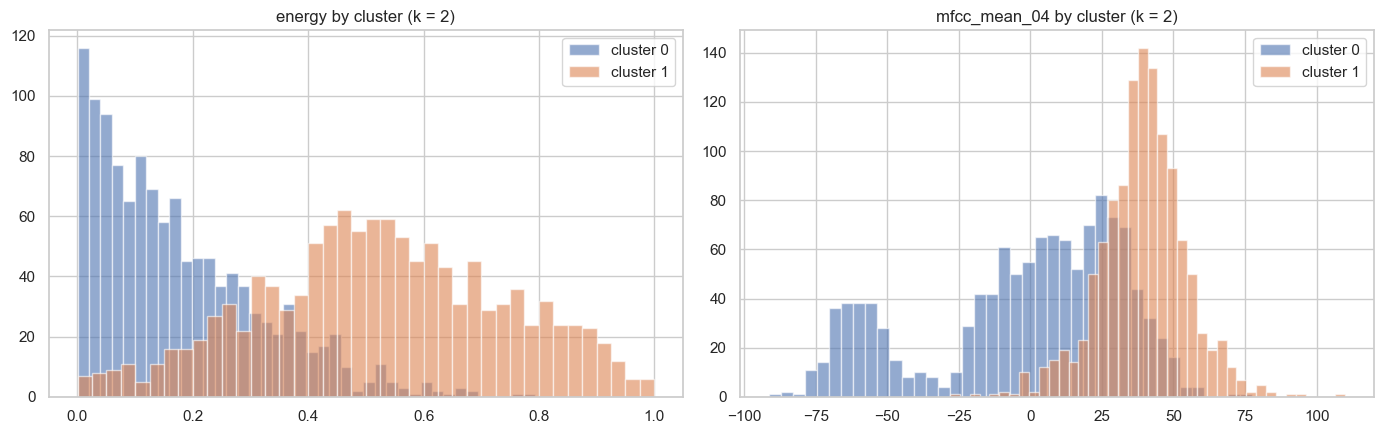

In [11]:
feat_names = X.columns
summary = []
for k in sorted({best_sil, best_ri, 4}):
    lab = labels_by_k[k]
    F = pd.Series(f_classif(X_scaled, lab)[0], index=feat_names).sort_values(ascending=False)
    rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(X_scaled, lab)
    imp = pd.Series(rf.feature_importances_, index=feat_names).sort_values(ascending=False)
    groups = imp.groupby(imp.index.map(feature_group)).sum().sort_values(ascending=False)
    summary.append({'k': k,
                    'top feature (ANOVA F)': f'{F.index[0]} (F = {F.iloc[0]:.0f})',
                    'next by F': ', '.join(F.index[1:5]),
                    'top 5 by random forest': ', '.join(imp.index[:5]),
                    'top groups by random forest': ', '.join(f'{g} {v:.2f}' for g, v in groups.head(3).items())})
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(summary).set_index('k'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, f in zip(axes, ['energy', 'mfcc_mean_04']):
    for c in np.unique(labels_by_k[best_sil]):
        ax.hist(features.loc[labels_by_k[best_sil] == c, f], bins=40, alpha=0.6, label=f'cluster {c}')
    ax.set_title(f'{f} by cluster (k = {best_sil})'); ax.legend()
plt.tight_layout(); plt.show()

In [12]:
# k = 6: is the top feature really about the tiny cluster?
lab6 = labels_by_k[6]
tiny = np.argmin(np.bincount(lab6))
col = list(feat_names).index('mfcc_kurtosis_01')
print(f'tiny cluster: {np.sum(lab6 == tiny)} tracks, z-scores of mfcc_kurtosis_01: {np.round(X_scaled[lab6 == tiny, col], 1)}')
print(f'all other tracks: max |z| = {np.abs(X_scaled[lab6 != tiny, col]).max():.1f}')
F_wo = pd.Series(f_classif(X_scaled[lab6 != tiny], lab6[lab6 != tiny])[0], index=feat_names)
print(f'F without the tiny cluster: mfcc_kurtosis_01 = {F_wo["mfcc_kurtosis_01"]:.0f}, '
      f'top feature = {F_wo.idxmax()} ({F_wo.max():.0f})')

tiny cluster: 4 tracks, z-scores of mfcc_kurtosis_01: [17.2 19.7 34.3 21.8]
all other tracks: max |z| = 1.6
F without the tiny cluster: mfcc_kurtosis_01 = 98, top feature = mfcc_mean_04 (1340)


- k = 2 (best by Silhouette): the strongest feature is **`energy`** (F = 2224, the largest of all 518), and it is also in the top 5 of the random forest. On the left histogram cluster 0 is mostly below ~0.3 (quiet, acoustic tracks), cluster 1 goes from 0.3 to 1.0 with a peak near 0.5 (loud ones), and they overlap mainly between 0.2 and 0.5. Next come MFCC coefficients (`mfcc_*_10`, `mfcc_*_06`) and `spectral_contrast_*_04`.
- k = 4 (the number of genres): **`mfcc_mean_04`** is first (F = 1483), then other statistics of the 4th MFCC coefficient and `mfcc_*_08`. The right histogram shows it for the k = 2 clusters: it separates them worse than `energy` (overlap between about 20 and 50), but values below -25 are almost only in cluster 0.
- k = 6 (best by Rand Index): formally the first feature is `mfcc_kurtosis_01` (F = 4501). But this comes from the 4-track outlier cluster from 5.1 (see the cell above). These 4 tracks have z-scores of 17-34 for this feature, while all other tracks are within ±1.6. Without them F drops from 4501 to 98, and `mfcc_mean_04` is first again. So this feature describes outliers, not music.
- By feature group (random forest), MFCC has the largest share for every k (34-42%), then `spectral_contrast` and chroma. The MFCC group is also the biggest (140 features), but MFCC is at the top of the single-feature rankings too, so it's not only because of the group size.

**Answer:** for the main split into two clusters the most important feature is **`energy`**. After that the clusters depend mostly on timbre (MFCC, especially the 4th coefficient). This makes sense, since these genres differ mostly in instruments and loudness, and less in key or tempo.